In [9]:
%load_ext autoreload
%autoreload 2

import sys, os
from pathlib import Path
REPO_DIR = Path(os.path.dirname(os.path.abspath(os.getcwd()))); print(f"Repo: {str(REPO_DIR)}")
sys.path.insert(0, str(REPO_DIR / "src"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Repo: /Users/tristanchaang/MIT/UROP-Traffic/mpc-traffic-flow


## Optimize and Save VSL

In [10]:
import logging, numpy as np
from traffic_flow.console import print_title, print_file
from traffic_flow import (load_params, load_scenario, optimize, save_result, 
                          CalSource, InitMode, Study, CalRef, Study)

def cc_optimize(dataset: str, date: str, calibration: CalRef, study, **kwargs):
  logging.getLogger("pyomo.core").setLevel(logging.ERROR)
  print_title("VSL Optimization")
  scenario = load_scenario(dataset, date)
  params = load_params(scenario, calibration=calibration)
  config = scenario.spec.to_mpc_config(**kwargs)
  result = optimize(scenario, params, config)
  save_result(result, calibration=calibration, study=study)

# regular run
if 0: [cc_optimize(
  dataset = "i24", date = x,
  calibration = CalRef(CalSource.FIXED_RAMPS, interval = None),
  study = None, speed_lb = 0,
  init_fixed = 150.0 # (InitMode.ADAPTIVE, 150.0)
) for x in ["11_30"]]
# safety_sweep
if 0: cc_optimize(
  dataset = "i24", date = "11_30",
  calibration = CalRef(CalSource.FIXED_RAMPS, interval = None),
  study = Study.SAFETY_SWEEP,
  safety_temporal = 0.7,
  safety_spatial = 25,
  initialize_vsl = np.load(REPO_DIR / "results_bu/i24/i24_11_30/calibration_static/fixed_ramping/safety_sweep/optimal_vsl_temp0.9_spat25.npy", allow_pickle=False),
  init_fixed = (InitMode.ADAPTIVE, 120, 100, 80, 60, 40)
)

## Plotting

In [11]:
from traffic_flow import CalRef, CalSource, InitMode, Study, load_one_result, LATEST_UPDATE
from traffic_flow.pipeline import replay
from traffic_flow.results.analysis import mape, rmse, run_analysis
from traffic_flow.results.plots import Plotter
from traffic_flow.console import print_title, print_table
import numpy as np

FIGURE_DIR = REPO_DIR / "figs" / "cc_plot"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

result = load_one_result("i24", "11_30", calibration=CalRef(CalSource.FIXED_RAMPS, interval = None), study = None)
result = replay(result, until_ff=LATEST_UPDATE)
stats = run_analysis(result)
traffic, uncontrolled, controlled = result.scenario.traffic, result.optimization.baseline, result.optimization.controlled

In [12]:
print_title("No Control")
n = len(traffic.velocity)
data = [("Velocity", traffic.velocity, uncontrolled.velocity[:n]), 
        ("Density", traffic.density, uncontrolled.density[:n]), 
        ("Flow", traffic.flow, uncontrolled.flow_per_lane[:n] * result.scenario.spec.lanes)]
print_table(headers=["Quantity", "Result"], data=[
  [name, f"MAPE {mape(a, b):.2f}%, RMSE {rmse(a, b):.2f}"] for name, a, b in data] + [
  ["Travel Time", f"{stats.gt_tt:.2f} veh-hr vs {stats.sim_window_tt:.2f} veh-hr (MAPE {stats.tts_error:.2f}%)"]
])

<< No Control >>
+-------------+---------------------------------------------+
| Quantity    | Result                                      |
+=============+=============================================+
| Velocity    | MAPE 58.06%, RMSE 17.68                     |
| Density     | MAPE 33.85%, RMSE 9.10                      |
| Flow        | MAPE 52.89%, RMSE 1751.24                   |
| Travel Time | 562.15 veh-hr vs 549.26 veh-hr (MAPE 2.29%) |
+-------------+---------------------------------------------+


In [13]:
spec, v_free = result.scenario.spec, result.params["v_free"]
if v_free.ndim == 2: v_free = v_free[:n]
observed_delay = (spec.L / traffic.velocity - spec.L / v_free) * 60
controlled_delay = (spec.L / controlled.velocity[:n] - spec.L / v_free) * 60
pct_decrease = np.where(observed_delay > 0.01, (observed_delay - controlled_delay) / observed_delay * 100, 0)

print_title("Optimized VSLs")
print_table(headers=["Metric", "Value"], data=[
  ['Total free flow travel time', f'{stats.ff_tt:.2f} veh-hrs'],
  ['Controllable congestion', f'{stats.cc:.2f}%'],
  ['Delay (ground truth)', f'{observed_delay.min():.2f} min - {observed_delay.max():.2f} min'],
  ['Pct decrease', f'{pct_decrease.min():.2f}% - {pct_decrease.max():.2f}%']
])

<< Optimized VSLs >>
+-----------------------------+-------------------------+
| Metric                      | Value                   |
+=============================+=========================+
| Total free flow travel time | 298.94 veh-hrs          |
| Controllable congestion     | 65.38%                  |
| Delay (ground truth)        | -0.10 min - 7.36 min    |
| Pct decrease                | -27849072.01% - 455.18% |
+-----------------------------+-------------------------+


Saved to figs/cc_plot/optimal_vsl.pdf


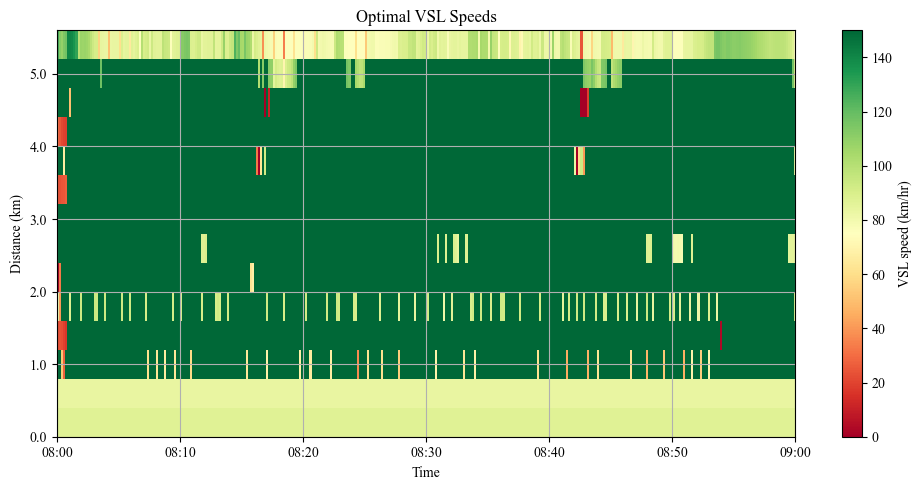

In [14]:
p = Plotter(1, 1)
display_vsl = np.where(result.optimization.vsl > v_free, 150, result.optimization.vsl)
p[0].plot_time_space(display_vsl, spec, v_free.max(), "Optimal VSL Speeds", ("v", "VSL speed (km/hr)"), grid=True)
p.savefig(FIGURE_DIR / "optimal_vsl.pdf")
p.show()

Saved to figs/cc_plot/controlled.pdf


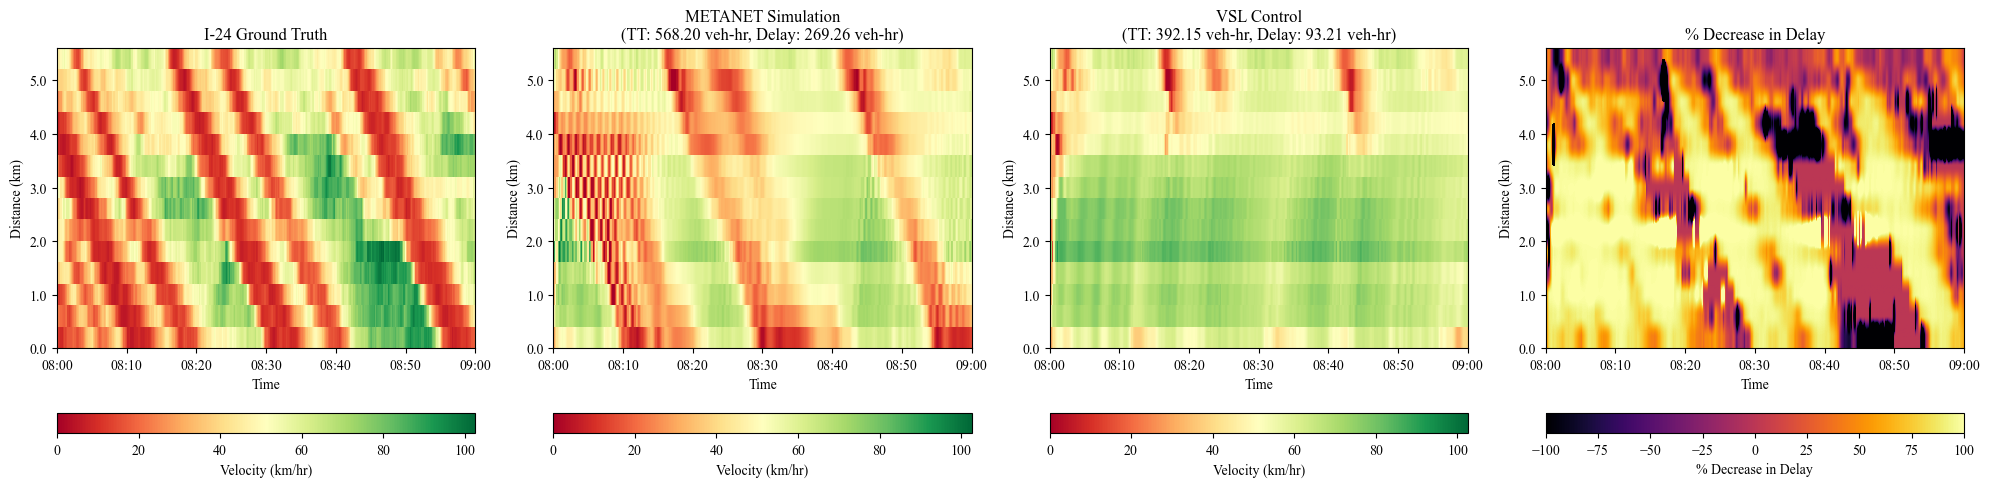

In [15]:
p = Plotter(1, 4)
uncontrolled, controlled = result.optimization.baseline, result.optimization.controlled
vmax = max(traffic.velocity.max(), result.optimization.baseline.velocity[:n].max())
for ax, mat, title in zip(p, (traffic.velocity, uncontrolled.velocity[:n], controlled.velocity[:n]), (
    f'{spec.freeway.upper().replace("I24", "I-24")} Ground Truth',
    f'METANET Simulation\n(TT: {uncontrolled.total_travel_time:.2f} veh-hr, Delay: {np.round(stats.sim_tt - stats.ff_tt, 2)} veh-hr)',
    f'VSL Control\n(TT: {controlled.total_travel_time:.2f} veh-hr, Delay: {np.round(stats.opt_tt - stats.ff_tt, 2)} veh-hr)'
)):
  ax.plot_time_space(mat, spec, vmax, title=title, colorbar=("h", "Velocity (km/hr)"))
p[3].plot_time_space(pct_decrease, spec, vmin=-100, vmax=100, title="% Decrease in Delay", 
                      colorbar=("h", "% Decrease in Delay"), cmap='inferno', smooth=True)
p.savefig(FIGURE_DIR / "controlled.pdf")
p.show()

Saved to figs/cc_plot/cc_reveal_evaluate.pdf


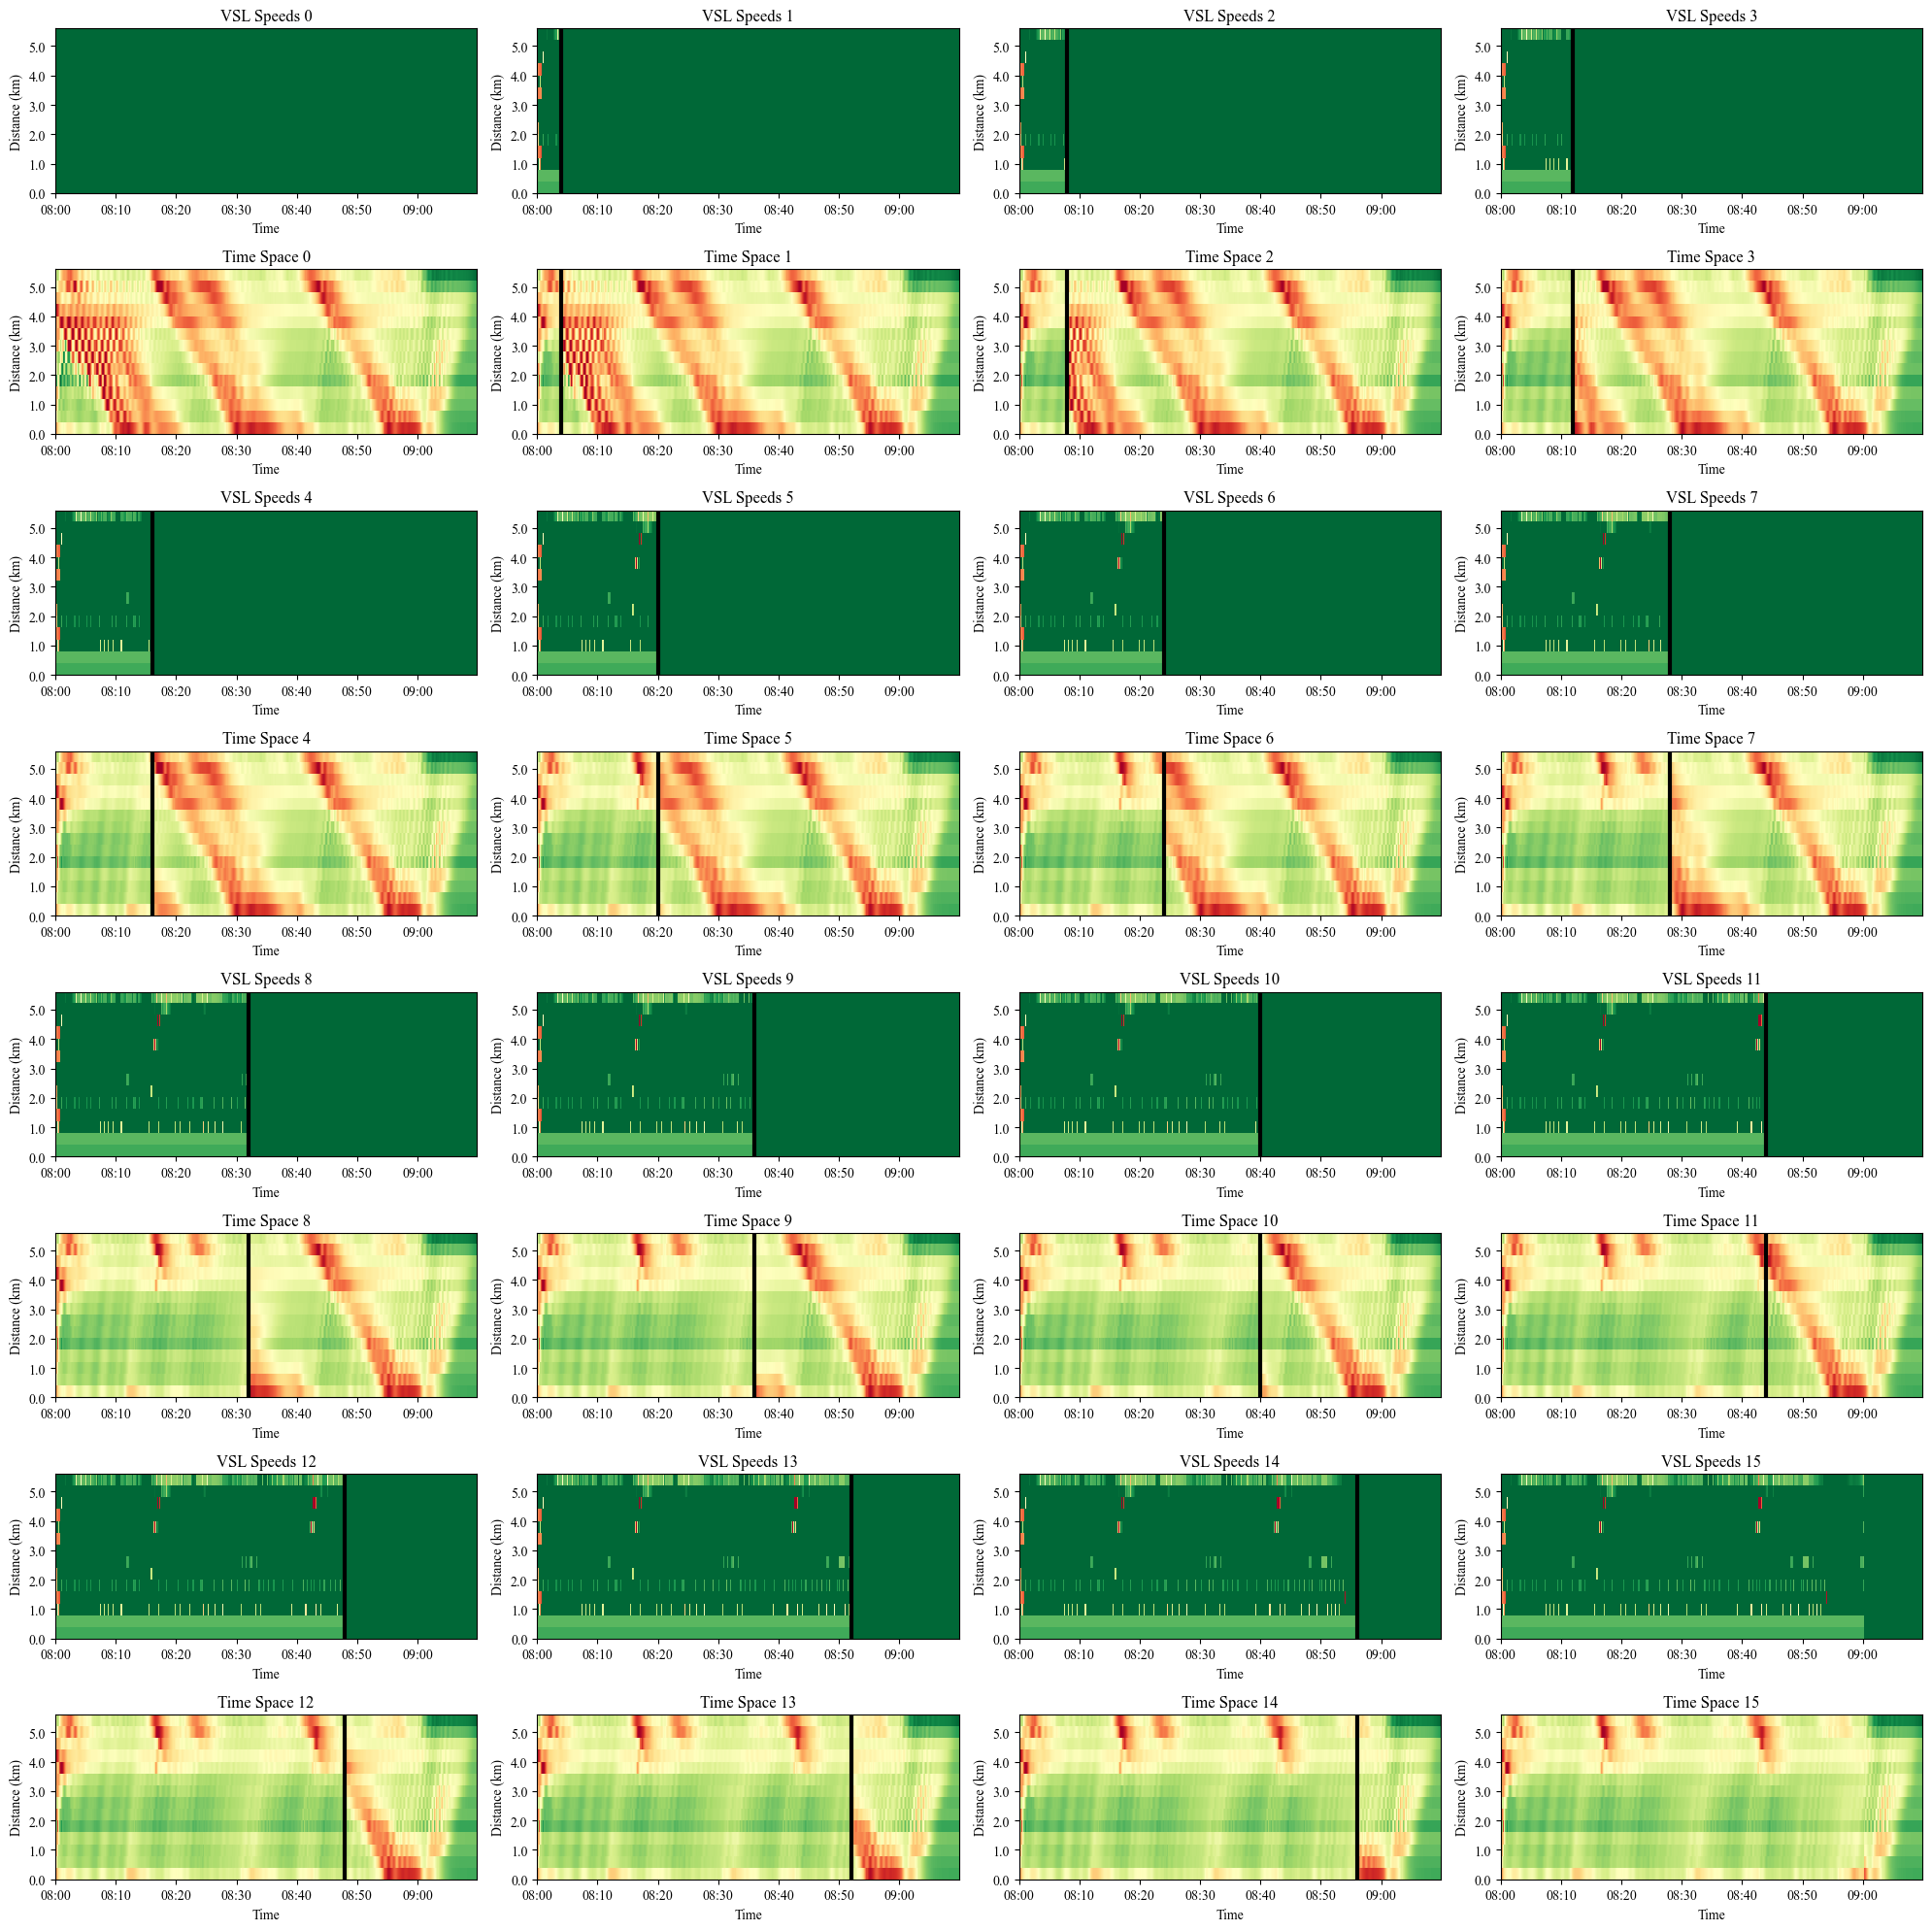

In [16]:
p = Plotter(8, 4, figsize=(20, 20))
vmax = max(result.scenario.traffic.velocity.max(), uncontrolled.velocity.max())
for k, t in enumerate(np.rint(np.linspace(0, n, 16)).astype(int)):
  batch, col = divmod(k, 4)
  for row, data, label in ((2 * batch, np.concatenate([display_vsl[:t], np.full_like(uncontrolled.velocity[t:], 150)]), "VSL Speeds"), 
                            (2 * batch + 1, np.concatenate([controlled.velocity[:t], uncontrolled.velocity[t:]]), "Time Space")):
    p[row, col].plot_time_space(data, result.scenario.spec, vmax, title=f"{label} {k}")
    if 0 < t < len(display_vsl): p[row, col].axvline(t, color="black", linewidth=3)
p.fig.tight_layout()
p.savefig(FIGURE_DIR / "cc_reveal_evaluate.pdf", dpi=150)
p.show()